Columns: ['date', 'Ex_rate']

First five rows:
            USD_AUD
date               
1990-01-01   0.7855
1990-01-02   0.7818
1990-01-03   0.7867
1990-01-04   0.7860
1990-01-05   0.7849

Dataset information:
<class 'pandas.DataFrame'>
DatetimeIndex: 7588 entries, 1990-01-01 to 2010-10-10
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   USD_AUD  7588 non-null   float64
dtypes: float64(1)
memory usage: 118.6 KB

Missing values:
USD_AUD    0
dtype: int64

Dataset shape: (7588, 1)


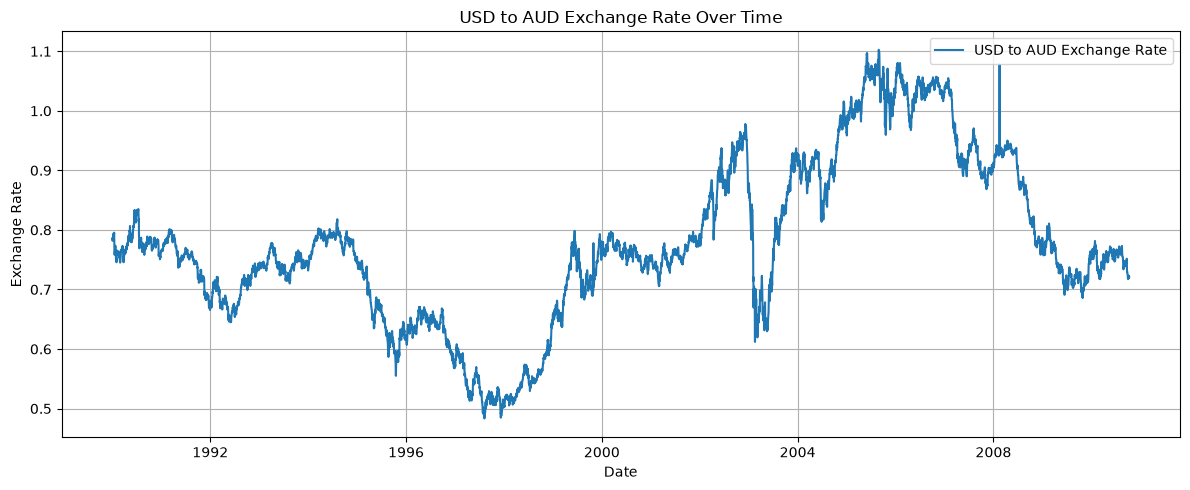


Descriptive Statistics:
count    7588.000000
mean        0.776974
std         0.136620
min         0.483297
25%         0.701422
50%         0.761377
75%         0.873477
max         1.102536
Name: USD_AUD, dtype: float64

ADF Stationarity Test
ADF Statistic: -1.6649941807381419
p-value: 0.4492327353597959
The series is non-stationary at the 5% significance level.
Differencing may be required for ARIMA.


C:\Users\adish\AppData\Local\Temp\ipykernel_32568\1411006873.py:108: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df["USD_AUD"])


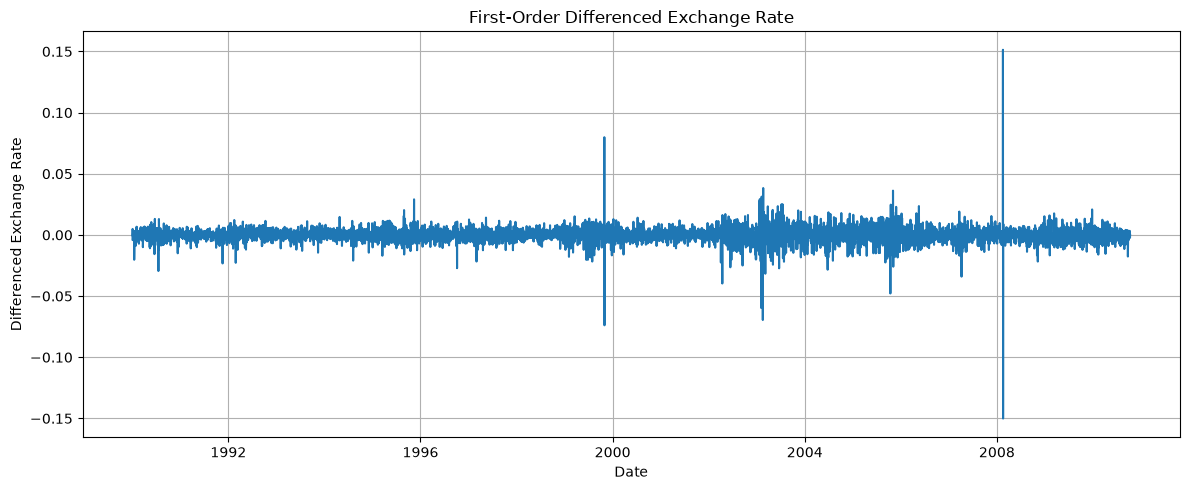


ADF Test After Differencing
ADF Statistic: -99.3934312011863
p-value: 0.0
The differenced series is stationary.


C:\Users\adish\AppData\Local\Temp\ipykernel_32568\1411006873.py:141: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(df_diff)


<Figure size 1200x500 with 0 Axes>

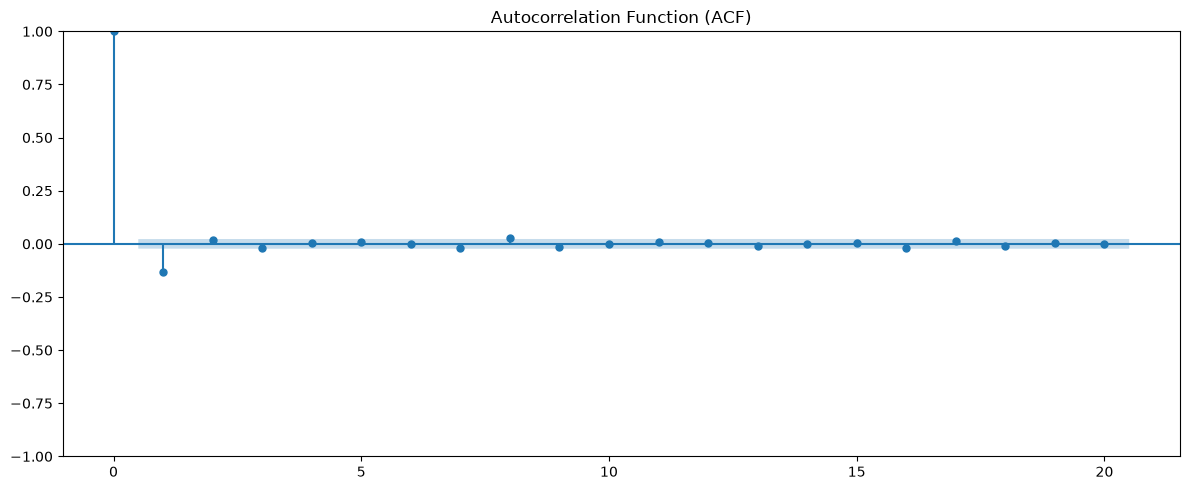

<Figure size 1200x500 with 0 Axes>

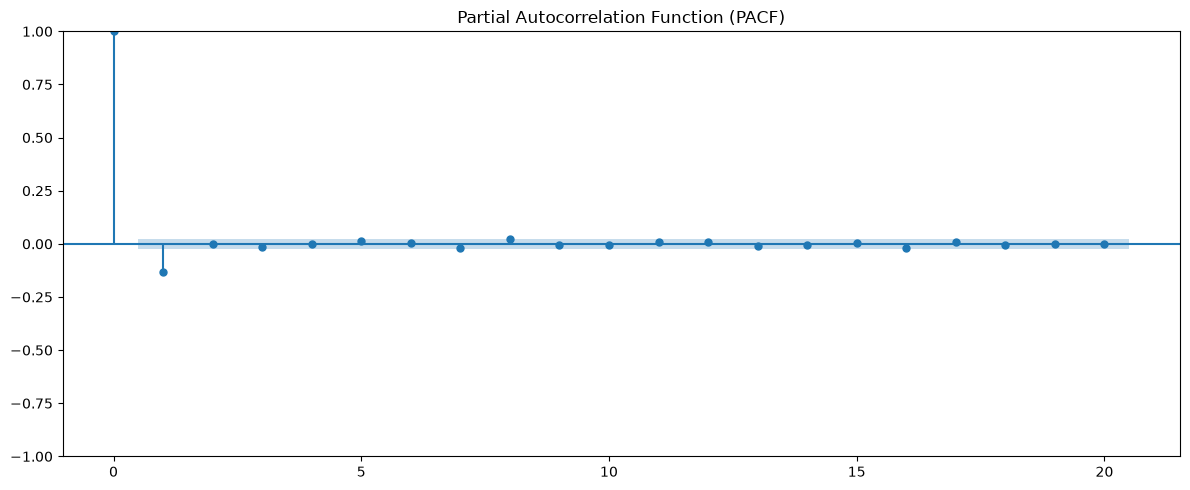


Initial ARIMA order: (1, 1, 1)

Training and Testing Data
Training size: 6070
Testing size: 1518
Training period: 1990-01-01 00:00:00 to 2006-08-14 00:00:00
Testing period: 2006-08-15 00:00:00 to 2010-10-10 00:00:00


C:\Users\adish\anaconda3\envs\ds_clustering\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\adish\anaconda3\envs\ds_clustering\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\adish\anaconda3\envs\ds_clustering\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



ARIMA Model Summary
                               SARIMAX Results                                
Dep. Variable:                USD_AUD   No. Observations:                 6070
Model:                 ARIMA(1, 1, 1)   Log Likelihood               22719.046
Date:                Tue, 20 Oct 2026   AIC                         -45432.092
Time:                        21:19:08   BIC                         -45411.959
Sample:                    01-01-1990   HQIC                        -45425.104
                         - 08-14-2006                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5972      0.062     -9.648      0.000      -0.719      -0.476
ma.L1          0.5398      0.064      8.430      0.000       0.414       0.665
sigma2      3.281e-05   1.95e-0

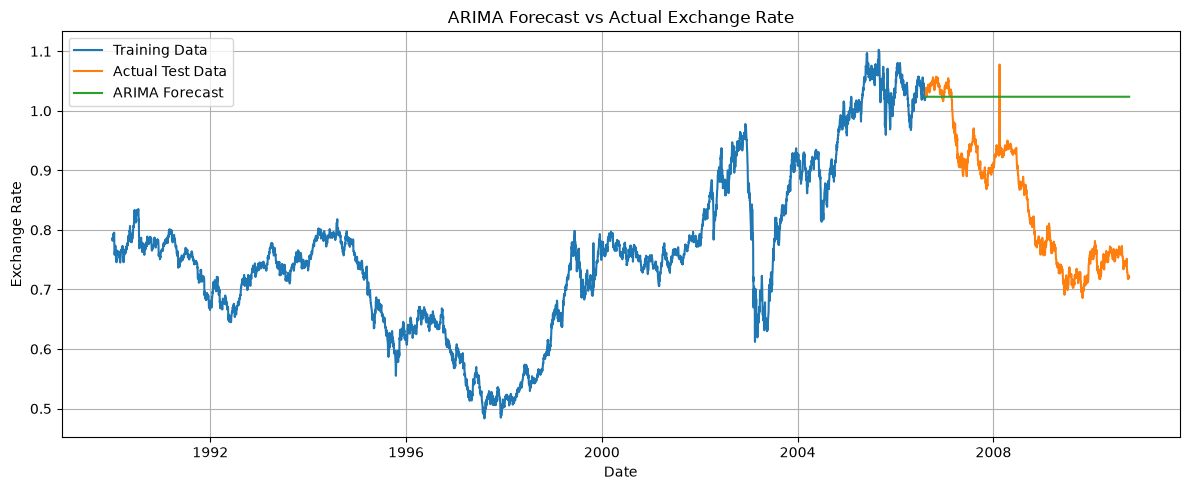

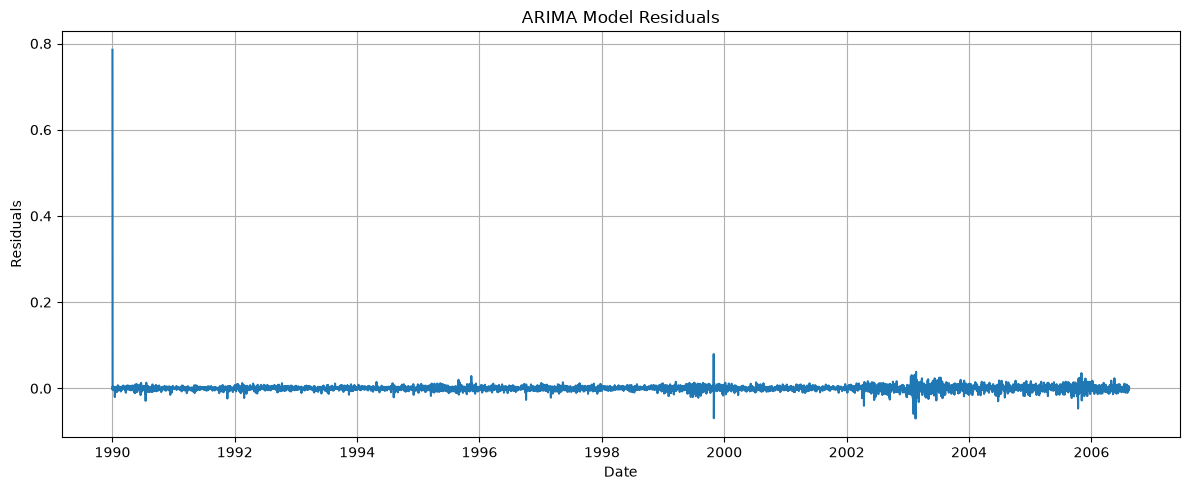

<Figure size 1200x500 with 0 Axes>

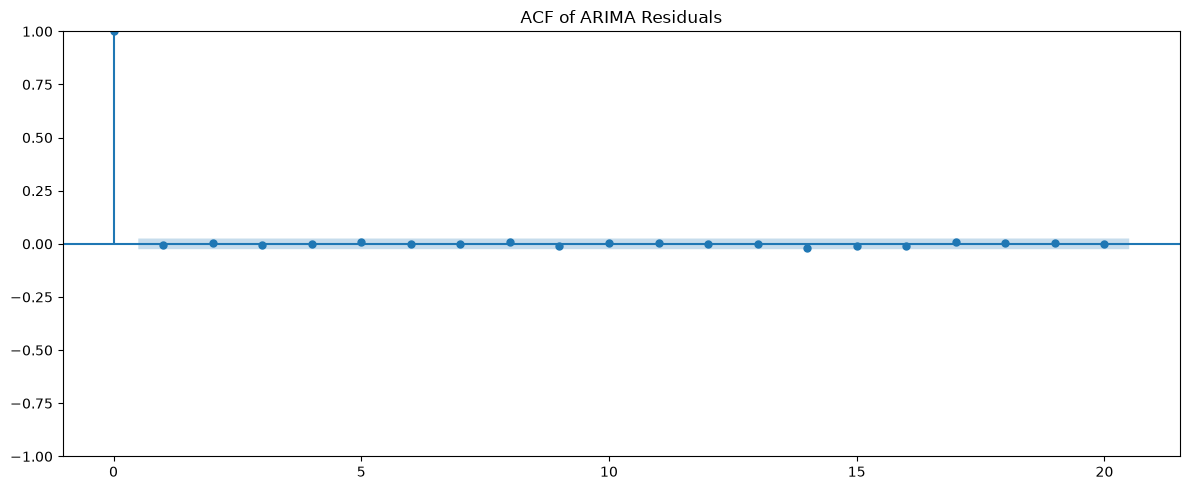


Residual Mean: 0.0001701004448971442
Residual Standard Deviation: 0.01159510292314015
Residual analysis helps identify patterns not captured by the ARIMA model.

Exponential Smoothing Model Fitted Successfully


C:\Users\adish\anaconda3\envs\ds_clustering\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


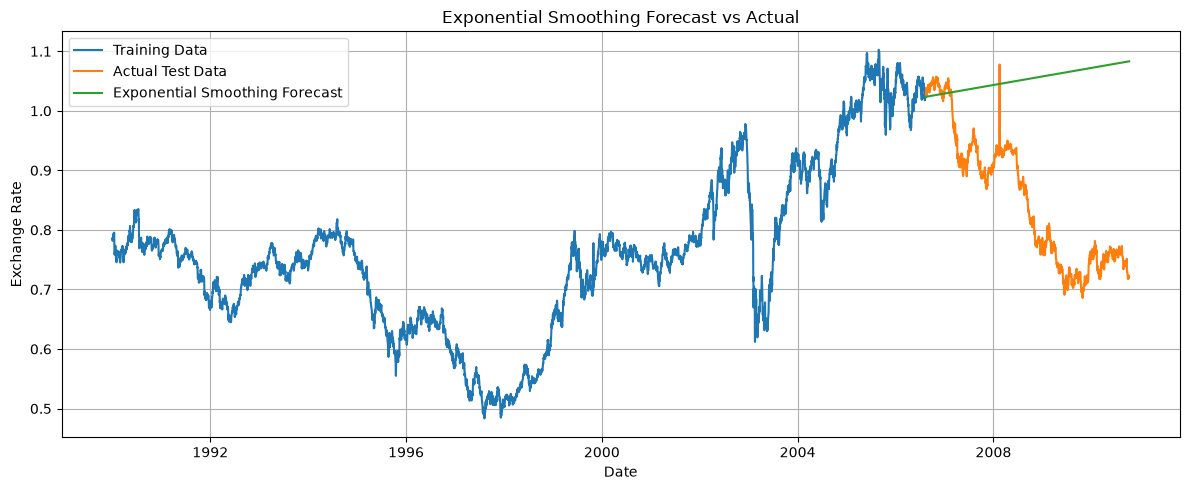


ARIMA PERFORMANCE
------------------------------
MAE : 0.17770970449120707
RMSE: 0.20543669659668565
MAPE: 22.79796617381075 %

EXPONENTIAL SMOOTHING PERFORMANCE
---------------------------------
MAE : 0.20659618956013914
RMSE: 0.23910442977645602
MAPE: 26.50866359588761 %

FINAL MODEL COMPARISON
                Model      MAE     RMSE      MAPE
                ARIMA 0.177710 0.205437 22.797966
Exponential Smoothing 0.206596 0.239104 26.508664

CONCLUSION
The model with the lower RMSE is: ARIMA
Corresponding RMSE: 0.20543669659668565

MAE measures the average absolute forecasting error.
RMSE penalizes larger forecasting errors more strongly.
MAPE expresses forecasting error as a percentage.

The model with lower error metrics generally provides more accurate forecasts on the test dataset.
ARIMA models autocorrelation and differencing, while Exponential Smoothing models level and trend.
The final model choice should also consider residual diagnostics and the forecasting requirements.


In [10]:
# ============================================================
# ASSIGNMENT 17: FORECASTING EXCHANGE RATES USING TIME SERIES
# ============================================================
# Objective:
# Forecast USD to Australian Dollar exchange rates using
# ARIMA and Exponential Smoothing.
# ============================================================


# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (12, 5)


# ============================================================
# 2. LOAD AND PREPARE DATASET
# ============================================================

# Load CSV dataset
df = pd.read_csv("C:/Users/adish/Downloads/exchange_rate (1).csv")

# Display column names
print("Columns:", df.columns.tolist())

# Convert date column to datetime
df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y %H:%M"
)

# Set date column as index
df.set_index("date", inplace=True)

# Rename exchange rate column
df.columns = ["USD_AUD"]

# Convert exchange rate to numeric values
df["USD_AUD"] = pd.to_numeric(
    df["USD_AUD"],
    errors="coerce"
)

# Handle missing values
df["USD_AUD"] = df["USD_AUD"].ffill()

# Remove any remaining missing values
df.dropna(inplace=True)

# Sort dates chronologically
df.sort_index(inplace=True)

# Display dataset
print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset shape:", df.shape)


# ============================================================
# 3. DATA EXPLORATION AND VISUALISATION
# ============================================================

# Plot exchange rate over time
plt.figure()

plt.plot(
    df.index,
    df["USD_AUD"],
    label="USD to AUD Exchange Rate"
)

plt.title("USD to AUD Exchange Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Display descriptive statistics
print("\nDescriptive Statistics:")
print(df["USD_AUD"].describe())


# ============================================================
# 4. STATIONARITY TEST (ADF TEST)
# ============================================================

adf_result = adfuller(df["USD_AUD"])

print("\nADF Stationarity Test")
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("The series is stationary at the 5% significance level.")
else:
    print("The series is non-stationary at the 5% significance level.")
    print("Differencing may be required for ARIMA.")


# ============================================================
# 5. DIFFERENCING
# ============================================================

# First-order differencing
df_diff = df["USD_AUD"].diff().dropna()

# Plot differenced series
plt.figure()

plt.plot(df_diff)

plt.title("First-Order Differenced Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Differenced Exchange Rate")
plt.grid(True)
plt.tight_layout()
plt.show()

# Test stationarity after differencing
adf_diff_result = adfuller(df_diff)

print("\nADF Test After Differencing")
print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])

if adf_diff_result[1] < 0.05:
    print("The differenced series is stationary.")
else:
    print("The differenced series may still be non-stationary.")


# ============================================================
# 6. ACF AND PACF PLOTS
# ============================================================

# ACF plot
plt.figure()

plot_acf(df_diff, lags=20)

plt.title("Autocorrelation Function (ACF)")
plt.tight_layout()
plt.show()

# PACF plot
plt.figure()

plot_pacf(df_diff, lags=20, method="ywm")

plt.title("Partial Autocorrelation Function (PACF)")
plt.tight_layout()
plt.show()

# Initial ARIMA parameter selection
# p = 1, d = 1, q = 1
# These are initial parameters and should be checked
# against the ACF and PACF plots.

print("\nInitial ARIMA order: (1, 1, 1)")


# ============================================================
# 7. TRAIN-TEST SPLIT
# ============================================================

# Use the first 80% of observations for training
# Use the remaining 20% for testing

train_size = int(len(df) * 0.8)

train = df["USD_AUD"].iloc[:train_size]
test = df["USD_AUD"].iloc[train_size:]

print("\nTraining and Testing Data")
print("Training size:", len(train))
print("Testing size:", len(test))

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())


# ============================================================
# 8. ARIMA MODEL FITTING
# ============================================================

# Fit ARIMA model with order (1, 1, 1)

arima_model = ARIMA(
    train,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

# Display model summary
print("\nARIMA Model Summary")
print(arima_fit.summary())


# ============================================================
# 9. ARIMA FORECASTING
# ============================================================

# Forecast values for the test period
arima_forecast = arima_fit.forecast(
    steps=len(test)
)

# Match forecast index with test dates
arima_forecast = pd.Series(
    np.asarray(arima_forecast),
    index=test.index,
    name="ARIMA Forecast"
)

# Plot actual and forecast values
plt.figure()

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Data"
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast"
)

plt.title("ARIMA Forecast vs Actual Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. RESIDUAL DIAGNOSTICS
# ============================================================

# Calculate residuals from fitted ARIMA model
residuals = arima_fit.resid

# Plot residuals
plt.figure()

plt.plot(residuals)

plt.title("ARIMA Model Residuals")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot residual autocorrelation
plt.figure()

plot_acf(residuals, lags=20)

plt.title("ACF of ARIMA Residuals")
plt.tight_layout()
plt.show()

# Residual mean
print("\nResidual Mean:", residuals.mean())

print(
    "Residual Standard Deviation:",
    residuals.std()
)

print(
    "Residual analysis helps identify patterns "
    "not captured by the ARIMA model."
)


# ============================================================
# 11. EXPONENTIAL SMOOTHING MODEL
# ============================================================

# Fit additive-trend Exponential Smoothing model
# No seasonal component is specified.

ets_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
)

ets_fit = ets_model.fit()

print("\nExponential Smoothing Model Fitted Successfully")


# ============================================================
# 12. EXPONENTIAL SMOOTHING FORECAST
# ============================================================

# Forecast the test period
ets_forecast = ets_fit.forecast(
    steps=len(test)
)

# Match forecast index with test dates
ets_forecast = pd.Series(
    np.asarray(ets_forecast),
    index=test.index,
    name="ETS Forecast"
)

# Plot actual and forecast values
plt.figure()

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Data"
)

plt.plot(
    ets_forecast.index,
    ets_forecast,
    label="Exponential Smoothing Forecast"
)

plt.title("Exponential Smoothing Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 13. MODEL EVALUATION METRICS
# ============================================================

def evaluate_model(actual, predicted):

    # Convert inputs into NumPy arrays
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    # Mean Absolute Error
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # Root Mean Squared Error
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # Mean Absolute Percentage Error
    # Exclude zero actual values to avoid division by zero
    nonzero = actual != 0

    if np.any(nonzero):

        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100

    else:
        mape = np.nan

    return mae, rmse, mape


# Evaluate ARIMA
arima_mae, arima_rmse, arima_mape = evaluate_model(
    test,
    arima_forecast
)

# Evaluate Exponential Smoothing
ets_mae, ets_rmse, ets_mape = evaluate_model(
    test,
    ets_forecast
)

# Print ARIMA performance
print("\nARIMA PERFORMANCE")
print("------------------------------")
print("MAE :", arima_mae)
print("RMSE:", arima_rmse)
print("MAPE:", arima_mape, "%")

# Print Exponential Smoothing performance
print("\nEXPONENTIAL SMOOTHING PERFORMANCE")
print("---------------------------------")
print("MAE :", ets_mae)
print("RMSE:", ets_rmse)
print("MAPE:", ets_mape, "%")


# ============================================================
# 14. MODEL COMPARISON AND CONCLUSION
# ============================================================

# Create comparison table
comparison = pd.DataFrame({

    "Model": [
        "ARIMA",
        "Exponential Smoothing"
    ],

    "MAE": [
        arima_mae,
        ets_mae
    ],

    "RMSE": [
        arima_rmse,
        ets_rmse
    ],

    "MAPE": [
        arima_mape,
        ets_mape
    ]

})

print("\nFINAL MODEL COMPARISON")
print("==============================")
print(comparison.to_string(index=False))

# Select the model with the lower RMSE
if arima_rmse < ets_rmse:

    best_model = "ARIMA"
    best_rmse = arima_rmse

elif ets_rmse < arima_rmse:

    best_model = "Exponential Smoothing"
    best_rmse = ets_rmse

else:

    best_model = "Both models have equal RMSE"
    best_rmse = arima_rmse

print("\nCONCLUSION")
print("==============================")

print(
    "The model with the lower RMSE is:",
    best_model
)

print("Corresponding RMSE:", best_rmse)

print(
    "\nMAE measures the average absolute forecasting error."
)

print(
    "RMSE penalizes larger forecasting errors more strongly."
)

print(
    "MAPE expresses forecasting error as a percentage."
)

print(
    "\nThe model with lower error metrics generally provides "
    "more accurate forecasts on the test dataset."
)

print(
    "ARIMA models autocorrelation and differencing, while "
    "Exponential Smoothing models level and trend."
)

print(
    "The final model choice should also consider residual "
    "diagnostics and the forecasting requirements."
)

#### Results and Discussion

The exchange-rate dataset was analysed using time-series techniques to understand its trends and forecasting behaviour. The Augmented Dickey-Fuller (ADF) test was used to examine stationarity. First-order differencing was then applied, and the differenced series was found to be stationary based on its ADF test result.

The ARIMA and Exponential Smoothing models were fitted using 80% of the observations for training, while the remaining 20% were used for testing. Their forecasts were compared with the actual exchange rates using MAE, RMSE and MAPE.

#### Model Comparison

The ARIMA model achieved an MAE of 0.177710, an RMSE of 0.205437 and a MAPE of 22.80%. The Exponential Smoothing model achieved an MAE of 0.206596, an RMSE of 0.239104 and a MAPE of 26.51%.

ARIMA performed better across all three evaluation metrics. Its lower MAE indicates smaller average absolute errors, while its lower RMSE indicates smaller errors under a metric that penalises larger deviations more heavily. Its lower MAPE also indicates a smaller average percentage error.

#### Advantages and Limitations

ARIMA: ARIMA can model autocorrelation and trends requiring differencing. However, its performance depends on appropriate parameter selection, and its forecasts may not capture sudden changes in exchange rates.

Exponential Smoothing: This method is relatively straightforward and can model the level and trend of a time series. However, its forecasting performance depends on the suitability of the selected smoothing method and may be limited when exchange-rate behaviour changes unexpectedly.

#### Conclusion

The analysis indicates that ARIMA performed better than Exponential Smoothing on the test dataset, as it achieved lower MAE, RMSE and MAPE values. Therefore, ARIMA is the preferred model among the two evaluated models for this particular experiment.

However, this conclusion is limited to the selected model configurations and test period. Further parameter tuning and residual diagnostics could help determine whether forecasting accuracy can be improved.